# CISC7204 Assignment 02: Project Proposal
## Tourism, Consumer Prices and Resident Real Earnings in Macao (2014–2025)

**Course:** CISC7204 Data Science and Data Visualization  

**Project Group:** ClassB-Pair13

**Group Members:**  
- LU YINHAI (Student ID: MC641724) 
- WANG CUI (Student ID: MC641431)  

### Background and Why We Chose This Topic
In Assignment 01, we studied the relationship between visitor arrivals and the Composite Consumer Price Index (CPI) in Macao from 2010 to 2025. That gave us an interesting preliminary view, but after reviewing our work, we realized two major limitations:

First, simply counting total visitor arrivals does not account for changes in Macao's resident population. Over the past decade, Macao's population grew from around 613,000 to over 688,000 in a very small land area (about 33.3 square kilometers). Having one million visitors feels very different depending on the size of the local population living in the city.

Second, CPI only measures price levels of goods and services, but it does not tell us whether local residents could actually afford those prices. A higher CPI does not automatically mean residents are worse off if their salaries grew faster than inflation.

To fix these two limitations, in Assignment 02 we decided to improve our project by downloading four separate Excel (.xlsx) files directly from the Macao Statistics and Census Service (DSEC) website: monthly visitor arrivals, monthly Composite CPI, quarterly population, and quarterly median employment earnings of full-time resident employees. This allows us to calculate two meaningful indicators: visitor intensity (visitors per 1,000 residents) and real earnings adjusted for inflation.


## 1. Our Research Questions

Our main research question is:
How did tourism intensity and resident purchasing power change together in Macao before, during, and after the COVID-19 pandemic from 2014 to 2025?

To answer this main question, we broke it down into three specific sub-questions:

1. Sub-question 1 (Visitor Pressure): How did population-standardized visitor intensity (visitors per 1,000 residents) change across the pre-pandemic period, the pandemic period, and the post-2023 recovery period?
2. Sub-question 2 (Real Purchasing Power): When we adjust nominal resident earnings by the Composite CPI, did local residents' real purchasing power improve over time, or did price increases cancel out their wage gains?
3. Sub-question 3 (Relationship Between the Two): Did tourism intensity and real earnings move together, and did this relationship look different during the pandemic shock compared to normal times?

### Why We Chose 2014–2025 (48 Quarters)
When we checked the official DSEC database, we discovered that the median earnings of full-time resident employees only started being published in the fourth quarter of 2013 (2013-Q4). 

Therefore, 2014 is the first full natural year where all four datasets are completely available.We chose 2014-Q1 to 2025-Q4 (exactly 48 quarters).

We split the 48 quarters into three periods:
- Pre-pandemic period: 2014-Q1 to 2019-Q4 (24 quarters) - normal tourism growth before COVID-19
- Pandemic disruption: 2020-Q1 to 2022-Q4 (12 quarters) - travel restrictions and border controls
- Recovery period: 2023-Q1 to 2025-Q4 (12 quarters) - border reopening and return of tourists


In [1]:
# Import libraries needed for data analysis and visualization
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Ignore minor warnings so the output stays clean
warnings.filterwarnings('ignore')

# Set figure quality and standard font
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']

# Create a folder for saving generated figures
figures_dir = Path("figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Define colors for the three periods to keep all charts consistent
period_colors = {
    "Pre-pandemic": "#1f77b4",        # Blue
    "Pandemic disruption": "#d62728", # Red
    "Recovery": "#2ca02c"             # Green
}

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Reading the Four Official Excel (.xlsx) Datasets

All four datasets were exported from the official Macao Statistics and Census Service (DSEC) database and stored as separate Excel (.xlsx) files in our `data/` folder:

1. `data/source/dsec_visitor_arrivals_indicator_14040.xlsx`
Monthly visitor arrivals from 2008 to present. We sum each set of 3 months to get quarterly visitor counts.

2. `data/source/dsec_composite_cpi_indicator_6003.xlsx`
Monthly Composite Consumer Price Index. We average each set of 3 months to get quarterly CPI.

3. `data/source/dsec_population_indicator_9003.xlsx`
Quarterly end-of-period total population in thousands of persons ('000 persons).

4. `data/source/dsec_resident_earnings_indicator_60599.xlsx`
Quarterly median monthly employment earnings of full-time resident employees (in MOP).

Official reference websites:
- DSEC Key Indicators: https://www.dsec.gov.mo/WebServices/ListOfKeyIndicatorID.aspx?lang=en-US
- DSEC TimeSeries Web Service: https://www.dsec.gov.mo/TimeSeriesDatabase.asmx


In [2]:
# Read the four separate official Excel (.xlsx) files from data/source
source_dir = Path("data")

df_vis_raw = pd.read_excel(source_dir / "dsec_visitor_arrivals_indicator_14040.xlsx")
df_cpi_raw = pd.read_excel(source_dir / "dsec_composite_cpi_indicator_6003.xlsx")
df_pop_raw = pd.read_excel(source_dir / "dsec_population_indicator_9003.xlsx")
df_earn_raw = pd.read_excel(source_dir / "dsec_resident_earnings_indicator_60599.xlsx")

print("Successfully loaded four Excel files:")
print("  Visitor arrivals file rows:", len(df_vis_raw))
print("  Composite CPI file rows:   ", len(df_cpi_raw))
print("  Population file rows:      ", len(df_pop_raw))
print("  Resident earnings rows:    ", len(df_earn_raw))

# 1. Filter monthly visitors and CPI to our 2014-2025 study window (144 months)
vis_monthly = df_vis_raw[(df_vis_raw["Period"] >= "2014-01") & (df_vis_raw["Period"] <= "2025-12")].copy()
cpi_monthly = df_cpi_raw[(df_cpi_raw["Period"] >= "2014-01") & (df_cpi_raw["Period"] <= "2025-12")].copy()

# 2. Aggregate monthly visitors to quarterly sum (3 months per quarter)
vis_monthly["Quarter"] = vis_monthly["Year"].astype(str) + "-Q" + vis_monthly["Quarter"].astype(str)
q_vis = vis_monthly.groupby("Quarter")["Visitor arrivals"].sum().reset_index()

# 3. Aggregate monthly CPI to quarterly arithmetic mean (3 months per quarter)
cpi_monthly["Quarter"] = cpi_monthly["Year"].astype(str) + "-Q" + cpi_monthly["Quarter"].astype(str)
q_cpi = cpi_monthly.groupby("Quarter")["Composite CPI"].mean().reset_index()
q_cpi.rename(columns={"Composite CPI": "Composite CPI (quarterly mean)"}, inplace=True)

# 4. Filter quarterly population and resident earnings to 2014-Q1 to 2025-Q4 (48 quarters)
q_pop = df_pop_raw[(df_pop_raw["Period"] >= "2014-Q1") & (df_pop_raw["Period"] <= "2025-Q4")][["Period", "Population"]].copy()
q_pop.rename(columns={"Period": "Quarter", "Population": "Population at quarter-end ('000)"}, inplace=True)

q_earn = df_earn_raw[(df_earn_raw["Period"] >= "2014-Q1") & (df_earn_raw["Period"] <= "2025-Q4")][["Period", "Median earnings"]].copy()
q_earn.rename(columns={"Period": "Quarter", "Median earnings": "Resident median earnings (MOP)"}, inplace=True)

# 5. Merge all four series on Quarter into a single master analysis dataframe
df = q_vis.merge(q_cpi, on="Quarter").merge(q_pop, on="Quarter").merge(q_earn, on="Quarter")

# 6. Add Phase label for each quarter
def assign_phase(quarter_str):
    year = int(quarter_str.split("-")[0])
    if year <= 2019:
        return "Pre-pandemic"
    elif year <= 2022:
        return "Pandemic disruption"
    return "Recovery"

df["Phase"] = df["Quarter"].apply(assign_phase)

# Check integrity
print("")
print("Merged quarterly dataset:")
print("  Total quarters:", len(df))
print("  Start quarter:", df["Quarter"].iloc[0])
print("  End quarter:  ", df["Quarter"].iloc[-1])
print("  Any missing values?", df.isna().sum().any())

# Preview first 5 rows
df.head()


Successfully loaded four Excel files:
  Visitor arrivals file rows: 224
  Composite CPI file rows:    344
  Population file rows:       106
  Resident earnings rows:     51

Merged quarterly dataset:
  Total quarters: 48
  Start quarter: 2014-Q1
  End quarter:   2025-Q4
  Any missing values? False


,Quarter,Visitor arrivals,Composite CPI (quarterly mean),Population at quarter-end ('000),Resident median earnings (MOP),Phase
0,2014-Q1,7690166,83.176667,613.2,16000,Pre-pandemic
1,2014-Q2,7593681,84.416667,621.7,15000,Pre-pandemic
2,2014-Q3,8245162,85.366667,628.4,16000,Pre-pandemic
3,2014-Q4,7996623,86.530000,636.2,16500,Pre-pandemic
4,2015-Q1,7412221,87.376667,640.7,18000,Pre-pandemic


## 3. Formulas and Metric Calculations

In order to answer our research questions, we calculated two main indicators:

1. Tourism Intensity (Visitors per 1,000 residents)
Formula:
Visitors per 1,000 residents = Quarterly visitor arrivals / Population in thousands

Since the DSEC population column is already reported in thousands of persons, dividing quarterly visitors by population directly gives the number of visitors per 1,000 residents.

2. Real Earnings (CPI-deflated MOP)
Formula:
Real earnings = (Nominal median earnings / Composite CPI) * 100

This formula divides nominal wages by the price index. If salary goes up from 16,000 to 20,000 MOP, but prices also go up by the same percentage, real earnings will stay flat. This tells us what the salary is actually worth in purchasing power.

3. Indexed Series (2014-Q1 = 100)
We set the first quarter (2014-Q1) equal to 100 so that we can easily compare the percentage changes of visitor intensity and real earnings on the same chart.


In [3]:
# Compute the derived indicators directly in pandas
base_visitors = df["Visitor arrivals"].iloc[0]
base_pop = df["Population at quarter-end ('000)"].iloc[0]
base_intensity = base_visitors / base_pop

base_nom_earnings = df["Resident median earnings (MOP)"].iloc[0]
base_cpi = df["Composite CPI (quarterly mean)"].iloc[0]
base_real_earnings = (base_nom_earnings / base_cpi) * 100

# Compute derived columns
df["Visitors per 1,000 residents"] = df["Visitor arrivals"] / df["Population at quarter-end ('000)"]
df["Real earnings (base-period MOP)"] = (df["Resident median earnings (MOP)"] / df["Composite CPI (quarterly mean)"]) * 100
df["Tourism intensity index (2014-Q1=100)"] = (df["Visitors per 1,000 residents"] / base_intensity) * 100
df["Real earnings index (2014-Q1=100)"] = (df["Real earnings (base-period MOP)"] / base_real_earnings) * 100

# Spot-check two representative quarters: 2019-Q4 (peak) and 2024-Q4 (recovery)
print("Manual check of two representative quarters:")
for test_q in ["2019-Q4", "2024-Q4"]:
    r = df[df["Quarter"] == test_q].iloc[0]
    p_name = r["Phase"]
    v_count = int(r["Visitor arrivals"])
    pop_val = r["Population at quarter-end ('000)"]
    calc_int = r["Visitors per 1,000 residents"]
    nom_val = int(r["Resident median earnings (MOP)"])
    cpi_val = r["Composite CPI (quarterly mean)"]
    real_val = r["Real earnings (base-period MOP)"]
    print(f"Quarter {test_q} ({p_name}):")
    print(f"  Visitors: {v_count:,}, Population: {pop_val}k -> Intensity: {calc_int:.1f} visitors per 1k residents")
    print(f"  Nominal earnings: {nom_val:,} MOP, CPI: {cpi_val:.2f} -> Real earnings: {real_val:.1f} MOP")

# Summary statistics for each of the three periods
period_summary = df.groupby("Phase")[["Visitors per 1,000 residents", "Composite CPI (quarterly mean)", 
                                      "Resident median earnings (MOP)", "Real earnings (base-period MOP)"]].mean().round(1)
print("")
print("Average values by period:")
period_summary


Manual check of two representative quarters:
Quarter 2019-Q4 (Pre-pandemic):
  Visitors: 9,203,275, Population: 679.6k -> Intensity: 13542.2 visitors per 1k residents
  Nominal earnings: 20,000 MOP, CPI: 98.29 -> Real earnings: 20347.9 MOP
Quarter 2024-Q4 (Recovery):
  Visitors: 9,007,736, Population: 688.3k -> Intensity: 13086.9 visitors per 1k residents
  Nominal earnings: 21,500 MOP, CPI: 100.83 -> Real earnings: 21323.0 MOP

Average values by period:


,"Visitors per 1,000 residents",Composite CPI (quarterly mean),Resident median earnings (MOP),Real earnings (base-period MOP)
Phase,,,,
Pandemic disruption,2354.6,98.5,20083.3,20393.8
Pre-pandemic,12859.6,91.4,18591.7,20311.7
Recovery,12551.6,100.7,21200.0,21049.2


## 4. Visualization F1: Monthly Trends of Visitors and CPI (2014–2025)

Before analyzing quarterly relationships, we first look at the monthly timeline from 2014 to 2025 (144 months). 

In this chart, we use two separate panels instead of a dual-axis line chart so the two different units (visitor counts and price index points) do not confuse the reader. The three shaded background colors mark our three periods: blue for pre-pandemic, red for the pandemic years, and green for post-2023 recovery.


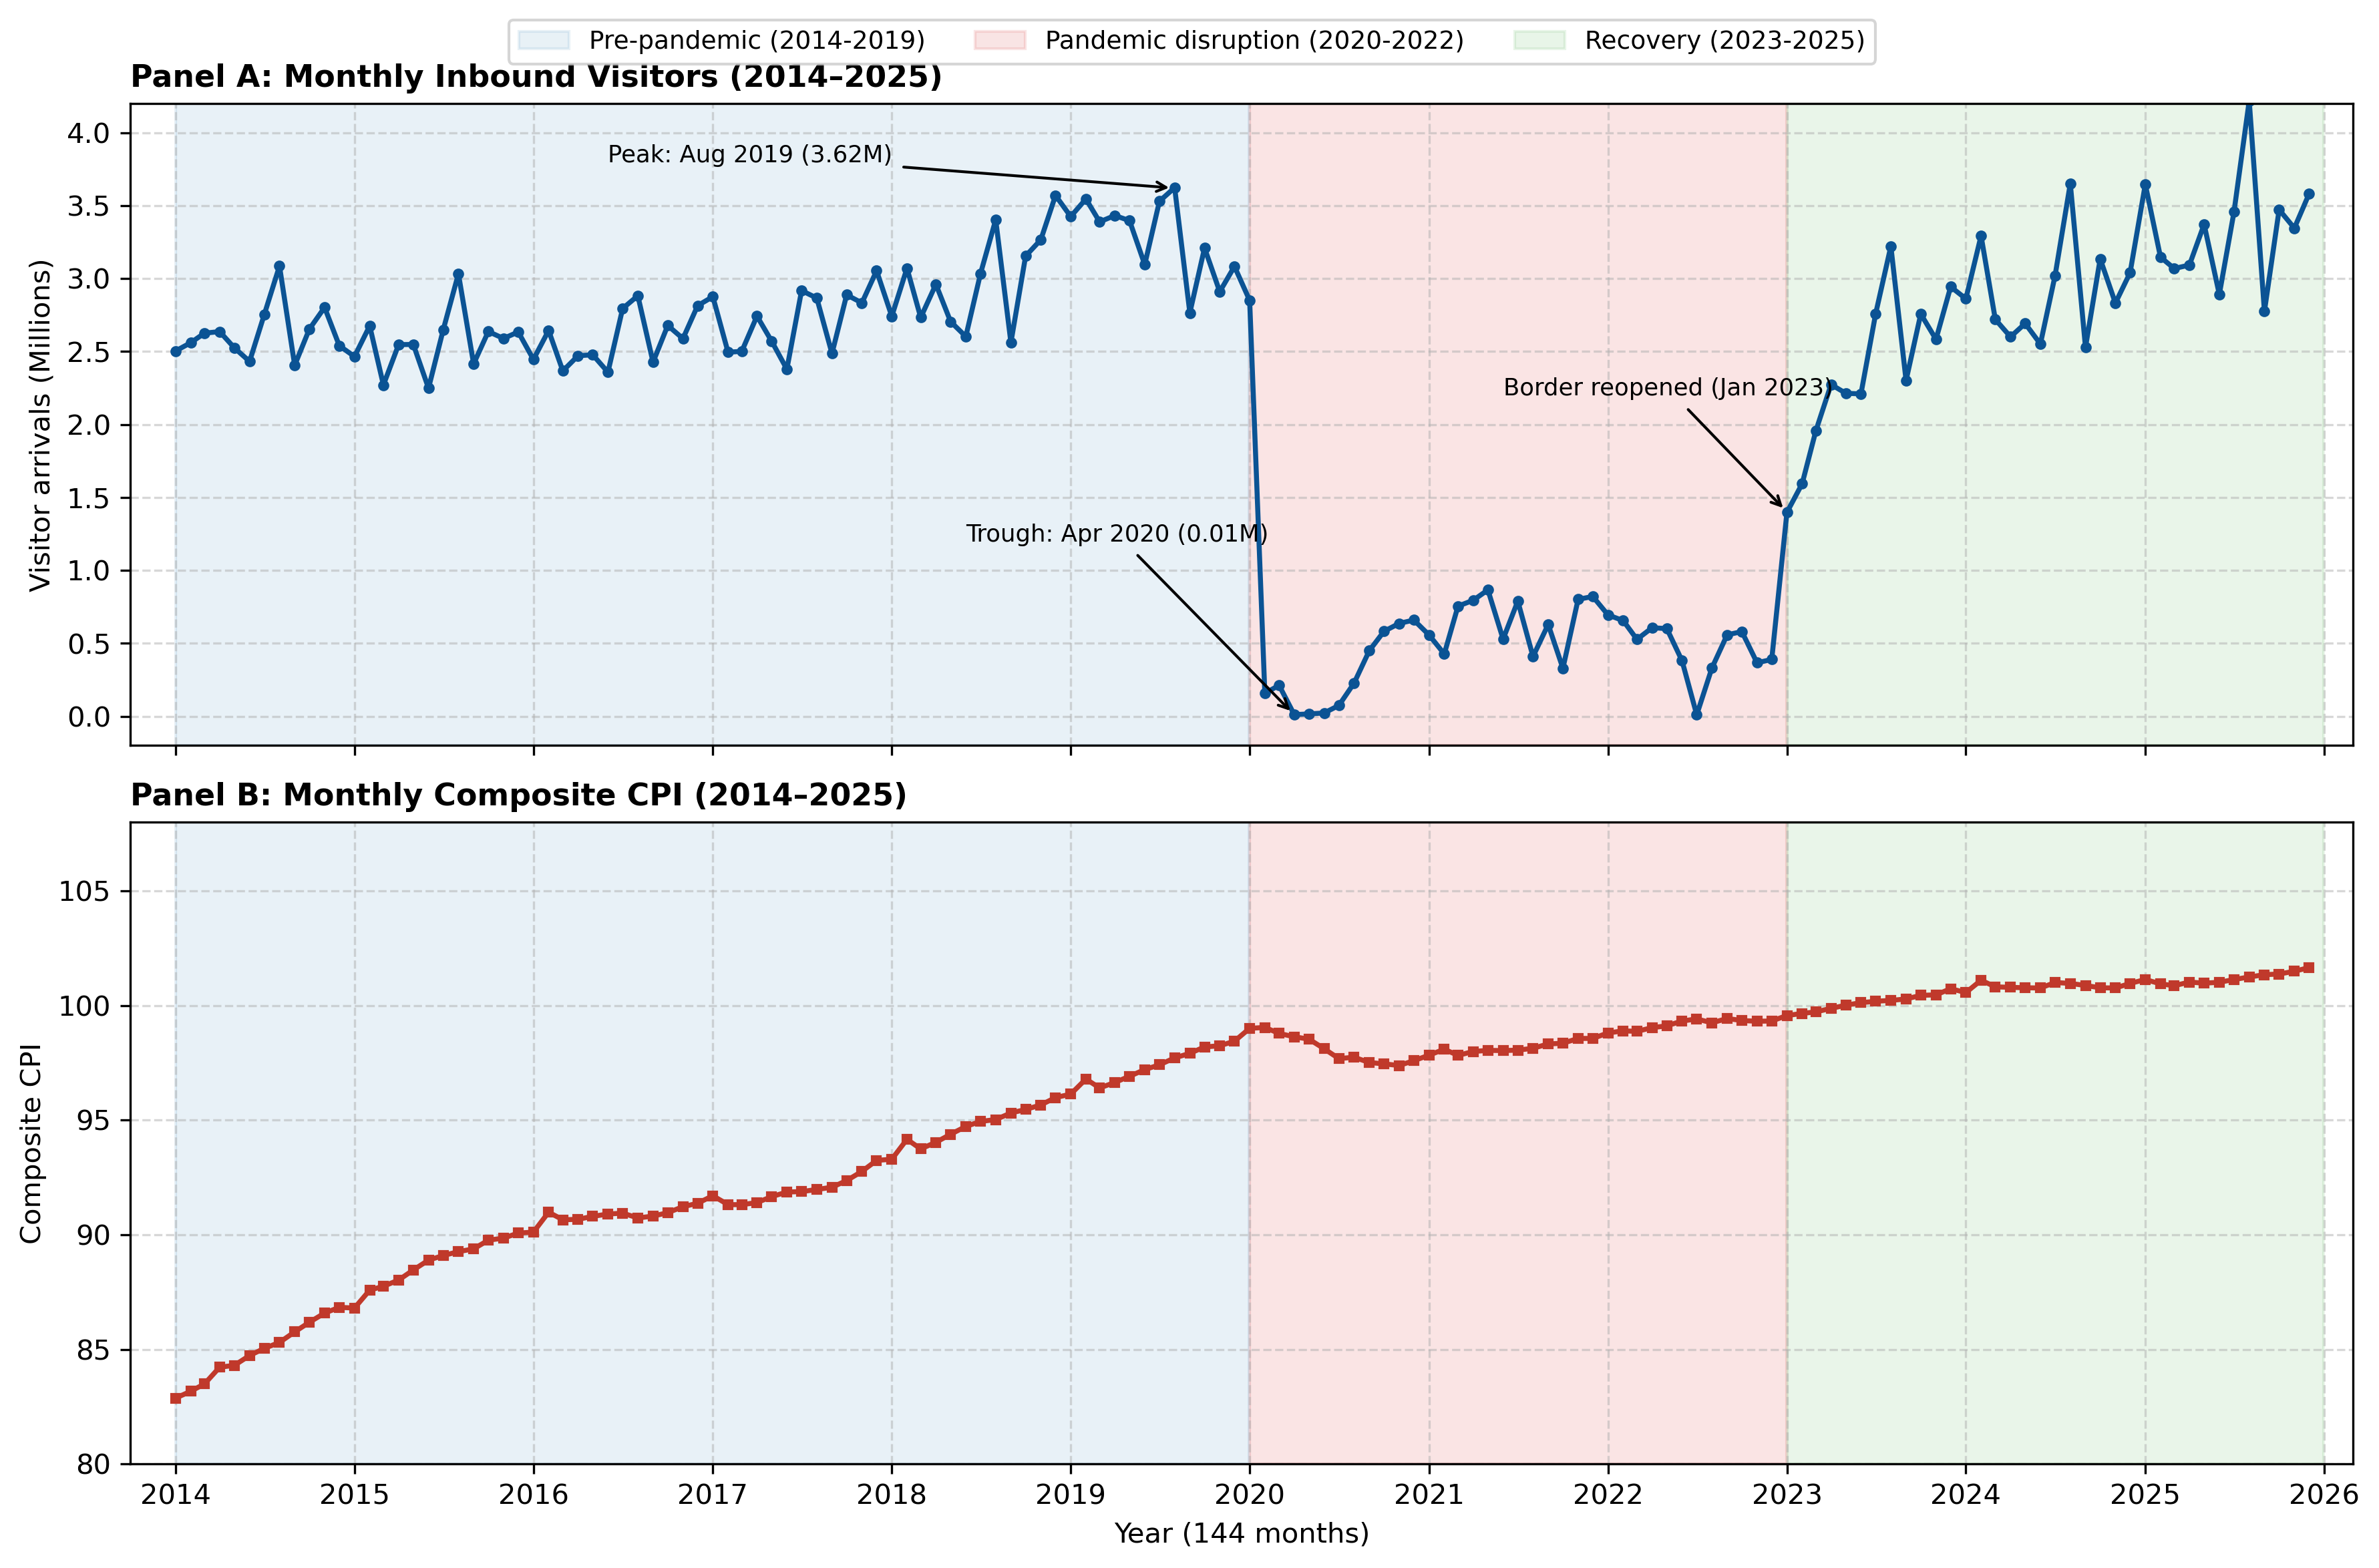

In [4]:
# Merge monthly visitors and CPI for the 144-month timeline plot
monthly_df = pd.merge(
    vis_monthly[["Period", "Year", "Month", "Visitor arrivals"]],
    cpi_monthly[["Period", "Composite CPI"]],
    on="Period"
).sort_values("Period").reset_index(drop=True)

monthly_df["Date"] = pd.to_datetime(monthly_df["Period"] + "-01")
monthly_df["Visitors_Millions"] = monthly_df["Visitor arrivals"] / 1e6

# Create two subplots sharing the x-axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Highlight the three periods
for ax in (ax1, ax2):
    ax.axvspan(pd.to_datetime("2014-01-01"), pd.to_datetime("2019-12-31"), color=period_colors["Pre-pandemic"], alpha=0.1, label="Pre-pandemic (2014-2019)")
    ax.axvspan(pd.to_datetime("2020-01-01"), pd.to_datetime("2022-12-31"), color=period_colors["Pandemic disruption"], alpha=0.12, label="Pandemic disruption (2020-2022)")
    ax.axvspan(pd.to_datetime("2023-01-01"), pd.to_datetime("2025-12-31"), color=period_colors["Recovery"], alpha=0.1, label="Recovery (2023-2025)")

# Top panel: Monthly visitor arrivals
ax1.plot(monthly_df["Date"], monthly_df["Visitors_Millions"], color="#0b5394", linewidth=1.8, marker="o", markersize=3)
ax1.set_ylabel("Visitor arrivals (Millions)", fontsize=10)
ax1.set_title("Panel A: Monthly Inbound Visitors (2014–2025)", fontsize=11, loc="left", fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.set_ylim(-0.2, 4.2)

# Add event annotations
ax1.annotate("Peak: Aug 2019 (3.62M)", xy=(pd.to_datetime("2019-08-01"), 3.62), xytext=(pd.to_datetime("2016-06-01"), 3.8),
             arrowprops=dict(facecolor="#333", arrowstyle="->", lw=1), fontsize=8.5)
ax1.annotate("Trough: Apr 2020 (0.01M)", xy=(pd.to_datetime("2020-04-01"), 0.01), xytext=(pd.to_datetime("2018-06-01"), 1.2),
             arrowprops=dict(facecolor="#d62728", arrowstyle="->", lw=1), fontsize=8.5)
ax1.annotate("Border reopened (Jan 2023)", xy=(pd.to_datetime("2023-01-01"), 1.4), xytext=(pd.to_datetime("2021-06-01"), 2.2),
             arrowprops=dict(facecolor="#2ca02c", arrowstyle="->", lw=1), fontsize=8.5)

# Bottom panel: Composite CPI
ax2.plot(monthly_df["Date"], monthly_df["Composite CPI"], color="#c0392b", linewidth=1.8, marker="s", markersize=3)
ax2.set_ylabel("Composite CPI", fontsize=10)
ax2.set_title("Panel B: Monthly Composite CPI (2014–2025)", fontsize=11, loc="left", fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.set_ylim(80, 108)

# Format the x-axis
ax2.set_xlim(pd.to_datetime("2013-10-01"), pd.to_datetime("2026-03-01"))
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax2.set_xlabel("Year (144 months)", fontsize=10)

# Add simple legend
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles[:3], labels[:3], loc="upper center", bbox_to_anchor=(0.5, 0.98), ncol=3, frameon=True, fontsize=9)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.savefig(figures_dir / "fig1_macro_trend_2014_2025.png", bbox_inches="tight")
plt.show()


### What We Notice from Figure 1

1. Before COVID (2014–2019):
Monthly visitors climbed steadily from about 2.5 million per month up to a record high of 3.62 million in August 2019. At the same time, CPI climbed from around 83 to 98. Both series trended upwards during this economic expansion.

2. During COVID (2020–2022):
When border restrictions were put in place in early 2020, visitor numbers plummeted by more than 99% (dropping to only 11,041 visitors in April 2020). However, CPI did not crash. Instead, prices flattened out between 98 and 100. This is because essential goods like food and household supplies still had fixed import and transport costs.

3. After 2023:
Once travel rules were relaxed in January 2023, visitor numbers bounced back very fast, reaching over 3 million visitors a month again by 2024 and 2025. CPI also resumed a modest upward climb.


## 5. Visualization F2: Quarterly Tourism Intensity per 1,000 Residents

This chart answers our first sub-question:
How did population-standardized visitor intensity change across the three periods?

Rather than looking at total visitor volume, we divide quarterly visitors by resident population (in thousands). This tells us how many visitors entered Macao for every 1,000 residents living in the city.


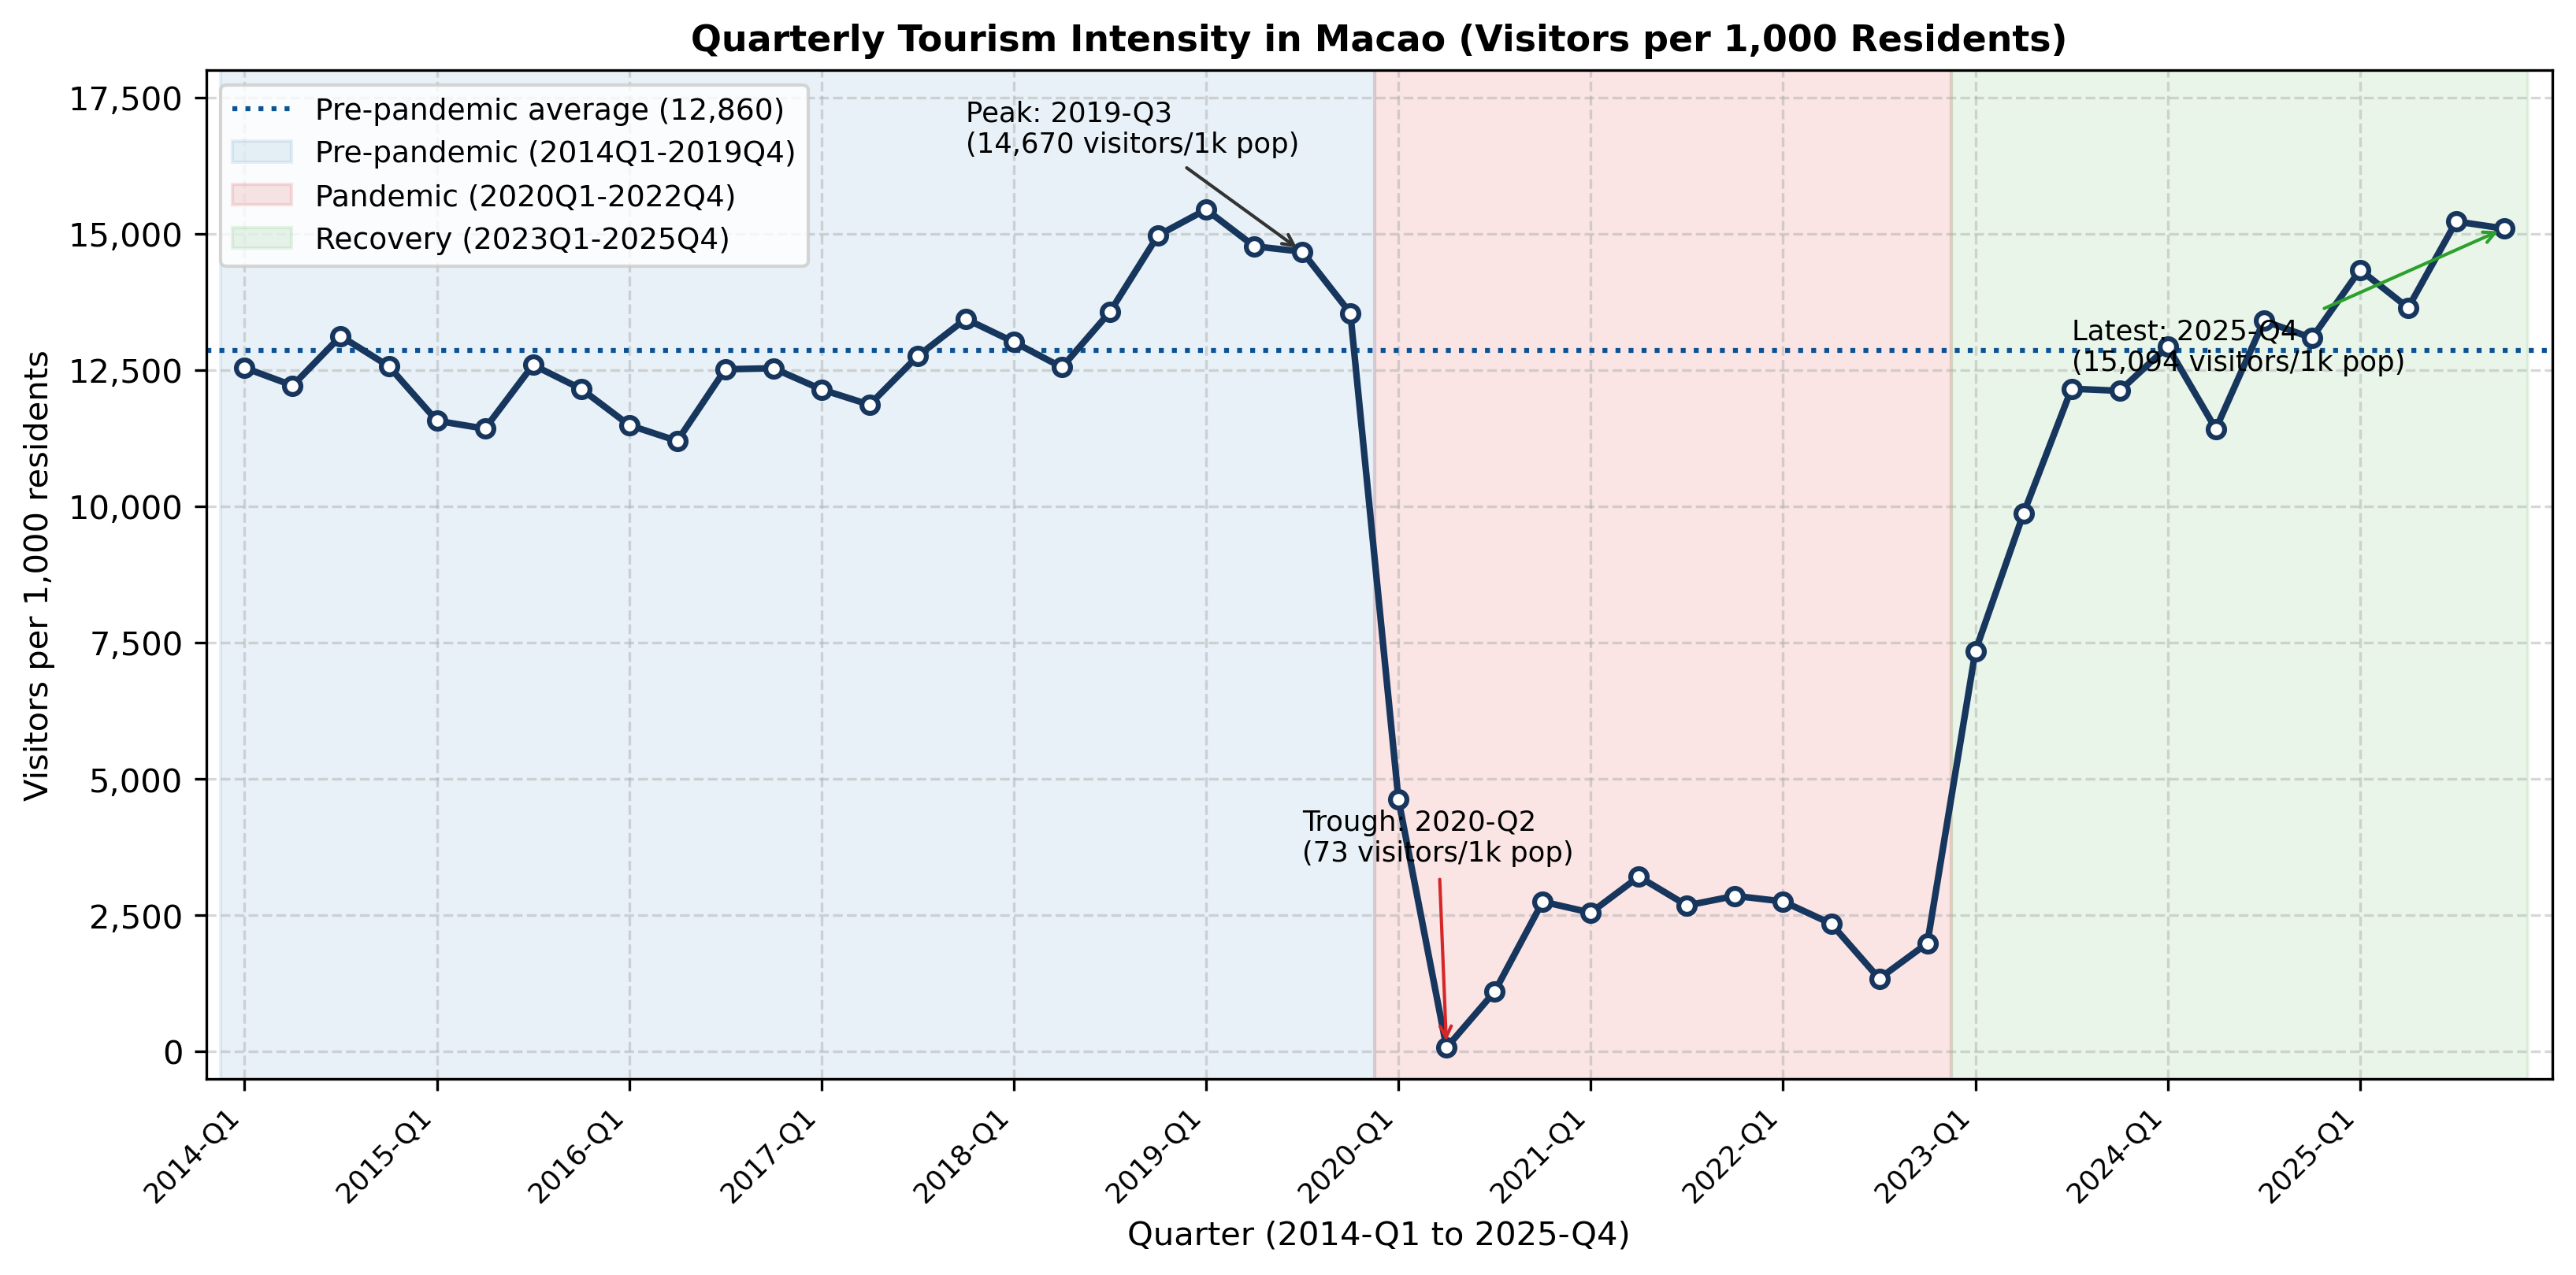

In [5]:
# Plot quarterly tourism intensity over all 48 quarters
fig, ax = plt.subplots(figsize=(11, 5.5))

quarters = df["Quarter"].values
intensity = df["Visitors per 1,000 residents"].values
x = np.arange(len(quarters))

# Background period shading
ax.axvspan(-0.5, 23.5, color=period_colors["Pre-pandemic"], alpha=0.1, label="Pre-pandemic (2014Q1-2019Q4)")
ax.axvspan(23.5, 35.5, color=period_colors["Pandemic disruption"], alpha=0.12, label="Pandemic (2020Q1-2022Q4)")
ax.axvspan(35.5, 47.5, color=period_colors["Recovery"], alpha=0.1, label="Recovery (2023Q1-2025Q4)")

# Historical average line
pre_avg = df[df["Phase"] == "Pre-pandemic"]["Visitors per 1,000 residents"].mean()
ax.axhline(pre_avg, color="#0b5394", linestyle=":", linewidth=1.5, label=f"Pre-pandemic average ({pre_avg:,.0f})")

# Main line plot
ax.plot(x, intensity, color="#17365d", linewidth=2, marker="o", markersize=5, markerfacecolor="white", markeredgewidth=1.5)

# Annotate key points
ax.annotate(f"Peak: 2019-Q3\n({intensity[22]:,.0f} visitors/1k pop)", xy=(22, intensity[22]), xytext=(15, 16500),
            arrowprops=dict(arrowstyle="->", color="#333"), fontsize=8.5)
ax.annotate(f"Trough: 2020-Q2\n({intensity[25]:,.0f} visitors/1k pop)", xy=(25, intensity[25]), xytext=(22, 3500),
            arrowprops=dict(arrowstyle="->", color="#d62728"), fontsize=8.5)
ax.annotate(f"Latest: 2025-Q4\n({intensity[47]:,.0f} visitors/1k pop)", xy=(47, intensity[47]), xytext=(38, 12500),
            arrowprops=dict(arrowstyle="->", color="#2ca02c"), fontsize=8.5)

# Labels and ticks
ax.set_title("Quarterly Tourism Intensity in Macao (Visitors per 1,000 Residents)", fontsize=11, fontweight="bold")
ax.set_ylabel("Visitors per 1,000 residents", fontsize=10)
ax.set_xlabel("Quarter (2014-Q1 to 2025-Q4)", fontsize=10)
ax.set_xticks(x[::4])
ax.set_xticklabels(quarters[::4], rotation=45, ha="right", fontsize=8.5)
ax.set_xlim(-0.8, 48)
ax.set_ylim(-500, 18000)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f"{int(val):,}"))
ax.grid(True, linestyle="--", alpha=0.5)

ax.legend(loc="upper left", fontsize=9, frameon=True)
plt.tight_layout()
plt.savefig(figures_dir / "fig2_tourism_intensity_quarterly.png", bbox_inches="tight")
plt.show()


### What We Notice from Figure 2 (Answering Sub-Question 1)

1. Extreme pre-pandemic tourist pressure:
Between 2014 and 2019, quarterly visitor intensity stayed between 11,500 and 15,300 visitors per 1,000 residents. In simple terms, this means that for every single resident living in Macao, about 11.5 to 15.3 tourists entered the city every quarter. This shows how crowded Macao was on a per-capita basis.

2. The sudden collapse:
In 2020-Q2, visitor intensity dropped all the way to 73.2 visitors per 1,000 residents. Across the entire three-year pandemic period, visitor intensity averaged only about 2,355 visitors per 1,000 residents per quarter.

3. Complete recovery:
After borders reopened, visitor intensity surged back up to 15,094 visitors per 1,000 residents by 2025-Q4. This shows that on a per-resident basis, tourist pressure is now fully back to its pre-pandemic peak.


## 6. Visualization F3: Nominal vs. Real Resident Earnings

This chart answers our second sub-question:
When we adjust nominal earnings by CPI inflation, did residents' actual purchasing power improve?

- Panel A shows nominal earnings in MOP compared directly with real earnings (earnings divided by CPI).
- Panel B converts both series and the CPI into index numbers (starting at 100 in 2014-Q1) so we can see how much of the salary increase was eroded by inflation.


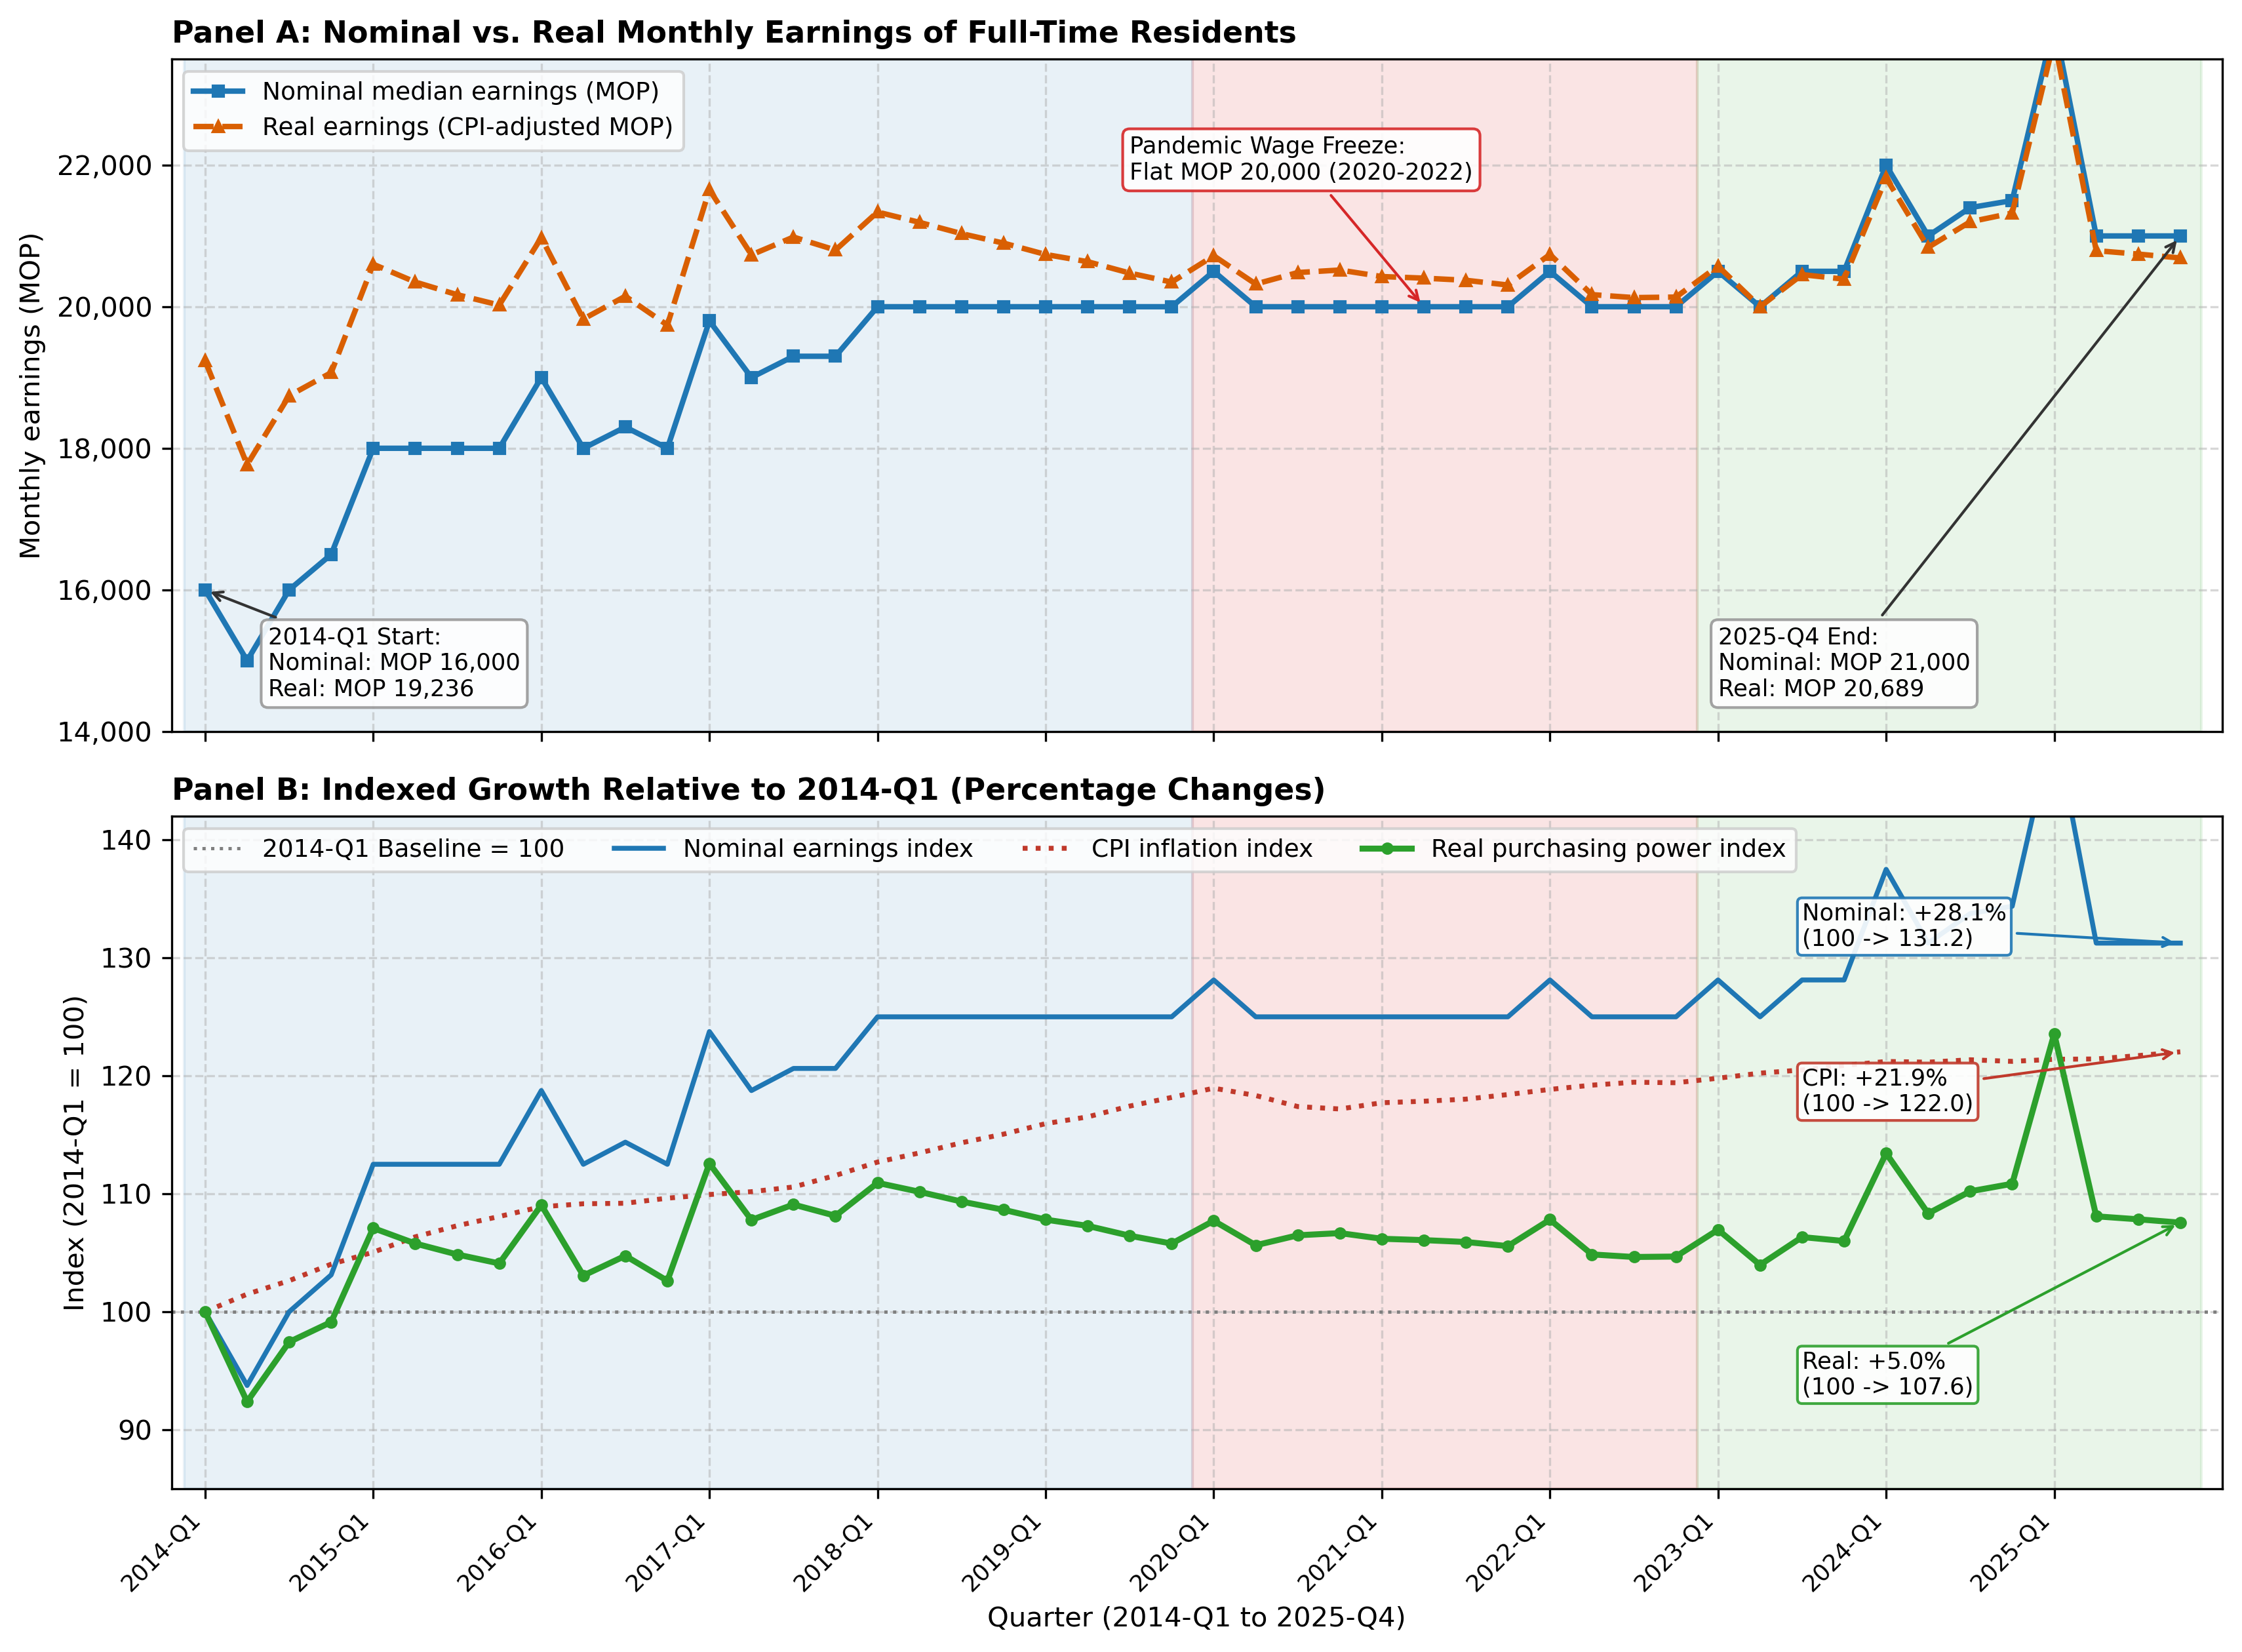

In [6]:
# Create two panels comparing nominal earnings, real earnings, and index growth
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11.5, 8.5), sharex=True)

nom_earnings = df["Resident median earnings (MOP)"].values
real_earnings = df["Real earnings (base-period MOP)"].values

# Period background shading
for ax in (ax1, ax2):
    ax.axvspan(-0.5, 23.5, color=period_colors["Pre-pandemic"], alpha=0.1)
    ax.axvspan(23.5, 35.5, color=period_colors["Pandemic disruption"], alpha=0.12)
    ax.axvspan(35.5, 47.5, color=period_colors["Recovery"], alpha=0.1)
    ax.grid(True, linestyle="--", alpha=0.5)

# Panel A: Dollar amounts (MOP)
ax1.plot(x, nom_earnings, color="#1f77b4", linewidth=2, marker="s", markersize=4, label="Nominal median earnings (MOP)")
ax1.plot(x, real_earnings, color="#d95f02", linewidth=2, marker="^", markersize=4, linestyle="--", label="Real earnings (CPI-adjusted MOP)")
ax1.set_ylabel("Monthly earnings (MOP)", fontsize=10)
ax1.set_title("Panel A: Nominal vs. Real Monthly Earnings of Full-Time Residents", fontsize=11, fontweight="bold", loc="left")
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f"{int(val):,}"))
ax1.set_ylim(14000, 23500)
ax1.legend(loc="upper left", fontsize=9, frameon=True)

# Annotate start and end on Panel A
ax1.annotate(f"2014-Q1 Start:\nNominal: MOP {nom_earnings[0]:,}\nReal: MOP {real_earnings[0]:,.0f}",
             xy=(0, nom_earnings[0]), xytext=(1.5, 14500),
             arrowprops=dict(arrowstyle="->", color="#333"), fontsize=8.5,
             bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffffff", edgecolor="#999", alpha=0.9))

ax1.annotate(f"2025-Q4 End:\nNominal: MOP {nom_earnings[-1]:,}\nReal: MOP {real_earnings[-1]:,.0f}",
             xy=(47, nom_earnings[-1]), xytext=(36, 14500),
             arrowprops=dict(arrowstyle="->", color="#333"), fontsize=8.5,
             bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffffff", edgecolor="#999", alpha=0.9))

ax1.annotate("Pandemic Wage Freeze:\nFlat MOP 20,000 (2020-2022)",
             xy=(29, 20000), xytext=(22, 21800),
             arrowprops=dict(arrowstyle="->", color="#d62728"), fontsize=8.5,
             bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffffff", edgecolor="#d62728", alpha=0.9))

# Panel B: Index comparison (2014Q1 = 100)
nom_index = (nom_earnings / nom_earnings[0]) * 100
cpi_index = (df["Composite CPI (quarterly mean)"].values / df["Composite CPI (quarterly mean)"].values[0]) * 100
real_index = (real_earnings / real_earnings[0]) * 100

ax2.axhline(100, color="gray", linestyle=":", linewidth=1.2, label="2014-Q1 Baseline = 100")
ax2.plot(x, nom_index, color="#1f77b4", linewidth=1.8, label="Nominal earnings index")
ax2.plot(x, cpi_index, color="#c0392b", linewidth=1.8, linestyle=":", label="CPI inflation index")
ax2.plot(x, real_index, color="#2ca02c", linewidth=2.2, marker="o", markersize=3.5, label="Real purchasing power index")

# Annotate exact percentage growth numbers from Cell 15
ax2.annotate(f"Nominal: +28.1%\n(100 -> {nom_index[-1]:.1f})", xy=(47, nom_index[-1]), xytext=(38, 131),
             arrowprops=dict(arrowstyle="->", color="#1f77b4"), fontsize=8.5,
             bbox=dict(boxstyle="round,pad=0.2", facecolor="#ffffff", edgecolor="#1f77b4", alpha=0.9))

ax2.annotate(f"CPI: +21.9%\n(100 -> {cpi_index[-1]:.1f})", xy=(47, cpi_index[-1]), xytext=(38, 117),
             arrowprops=dict(arrowstyle="->", color="#c0392b"), fontsize=8.5,
             bbox=dict(boxstyle="round,pad=0.2", facecolor="#ffffff", edgecolor="#c0392b", alpha=0.9))

ax2.annotate(f"Real: +5.0%\n(100 -> {real_index[-1]:.1f})", xy=(47, real_index[-1]), xytext=(38, 93),
             arrowprops=dict(arrowstyle="->", color="#2ca02c"), fontsize=8.5,
             bbox=dict(boxstyle="round,pad=0.2", facecolor="#ffffff", edgecolor="#2ca02c", alpha=0.9))

ax2.set_ylabel("Index (2014-Q1 = 100)", fontsize=10)
ax2.set_xlabel("Quarter (2014-Q1 to 2025-Q4)", fontsize=10)
ax2.set_title("Panel B: Indexed Growth Relative to 2014-Q1 (Percentage Changes)", fontsize=11, fontweight="bold", loc="left")
ax2.set_xticks(x[::4])
ax2.set_xticklabels(quarters[::4], rotation=45, ha="right", fontsize=8.5)
ax2.set_xlim(-0.8, 48)
ax2.set_ylim(85, 142)
ax2.legend(loc="upper left", fontsize=9, frameon=True, ncol=4)

plt.tight_layout()
plt.savefig(figures_dir / "fig3_resident_earnings_nominal_vs_real.png", bbox_inches="tight")
plt.show()


### What We Notice from Figure 3 (Answering Sub-Question 2)

1. Nominal earnings grew by 28%:
In nominal terms, median monthly earnings of full-time resident employees increased from 16,000 MOP in 2014-Q1 to 20,500 MOP in 2025-Q4, which looks like a solid gain of 28.1% (annotated as +28.1% on Panel B).

2. But CPI inflation rose by 22%:
Over the same period, the Composite CPI rose from 83.18 to 101.45, an increase of 21.9% (annotated as +21.9% on Panel B).

3. Real purchasing power only grew by 5%:
When we look at real earnings (Panel B), the green line shows that purchasing power only grew from 19,236 MOP to 20,207 MOP—a total increase of just 5.0% over 12 years (annotated as +5.0% on Panel B). That equals an average real improvement of less than 0.5% per year. Most of the nominal salary increase went directly into paying for higher prices.

4. Salary during the pandemic:
During the three pandemic years (2020–2022), nominal resident median earnings stayed completely flat at 20,000 MOP every single quarter (annotated on Panel A). Because inflation was also very low, real earnings remained stable. This suggests full-time resident workers who kept their jobs had relatively stable base pay, though they may have lost bonuses or overtime.


## 7. Visualization F4: Relationship Between Tourism Intensity and Real Earnings

This chart answers our third sub-question:
Did tourism intensity and real resident earnings move together, and did this relationship differ across the three periods?


If we simply run one overall correlation across all 48 quarters, we get r = +0.15, which seems to say there is almost no relationship. But plotting the data points by period with separate regression lines shows a much clearer picture.


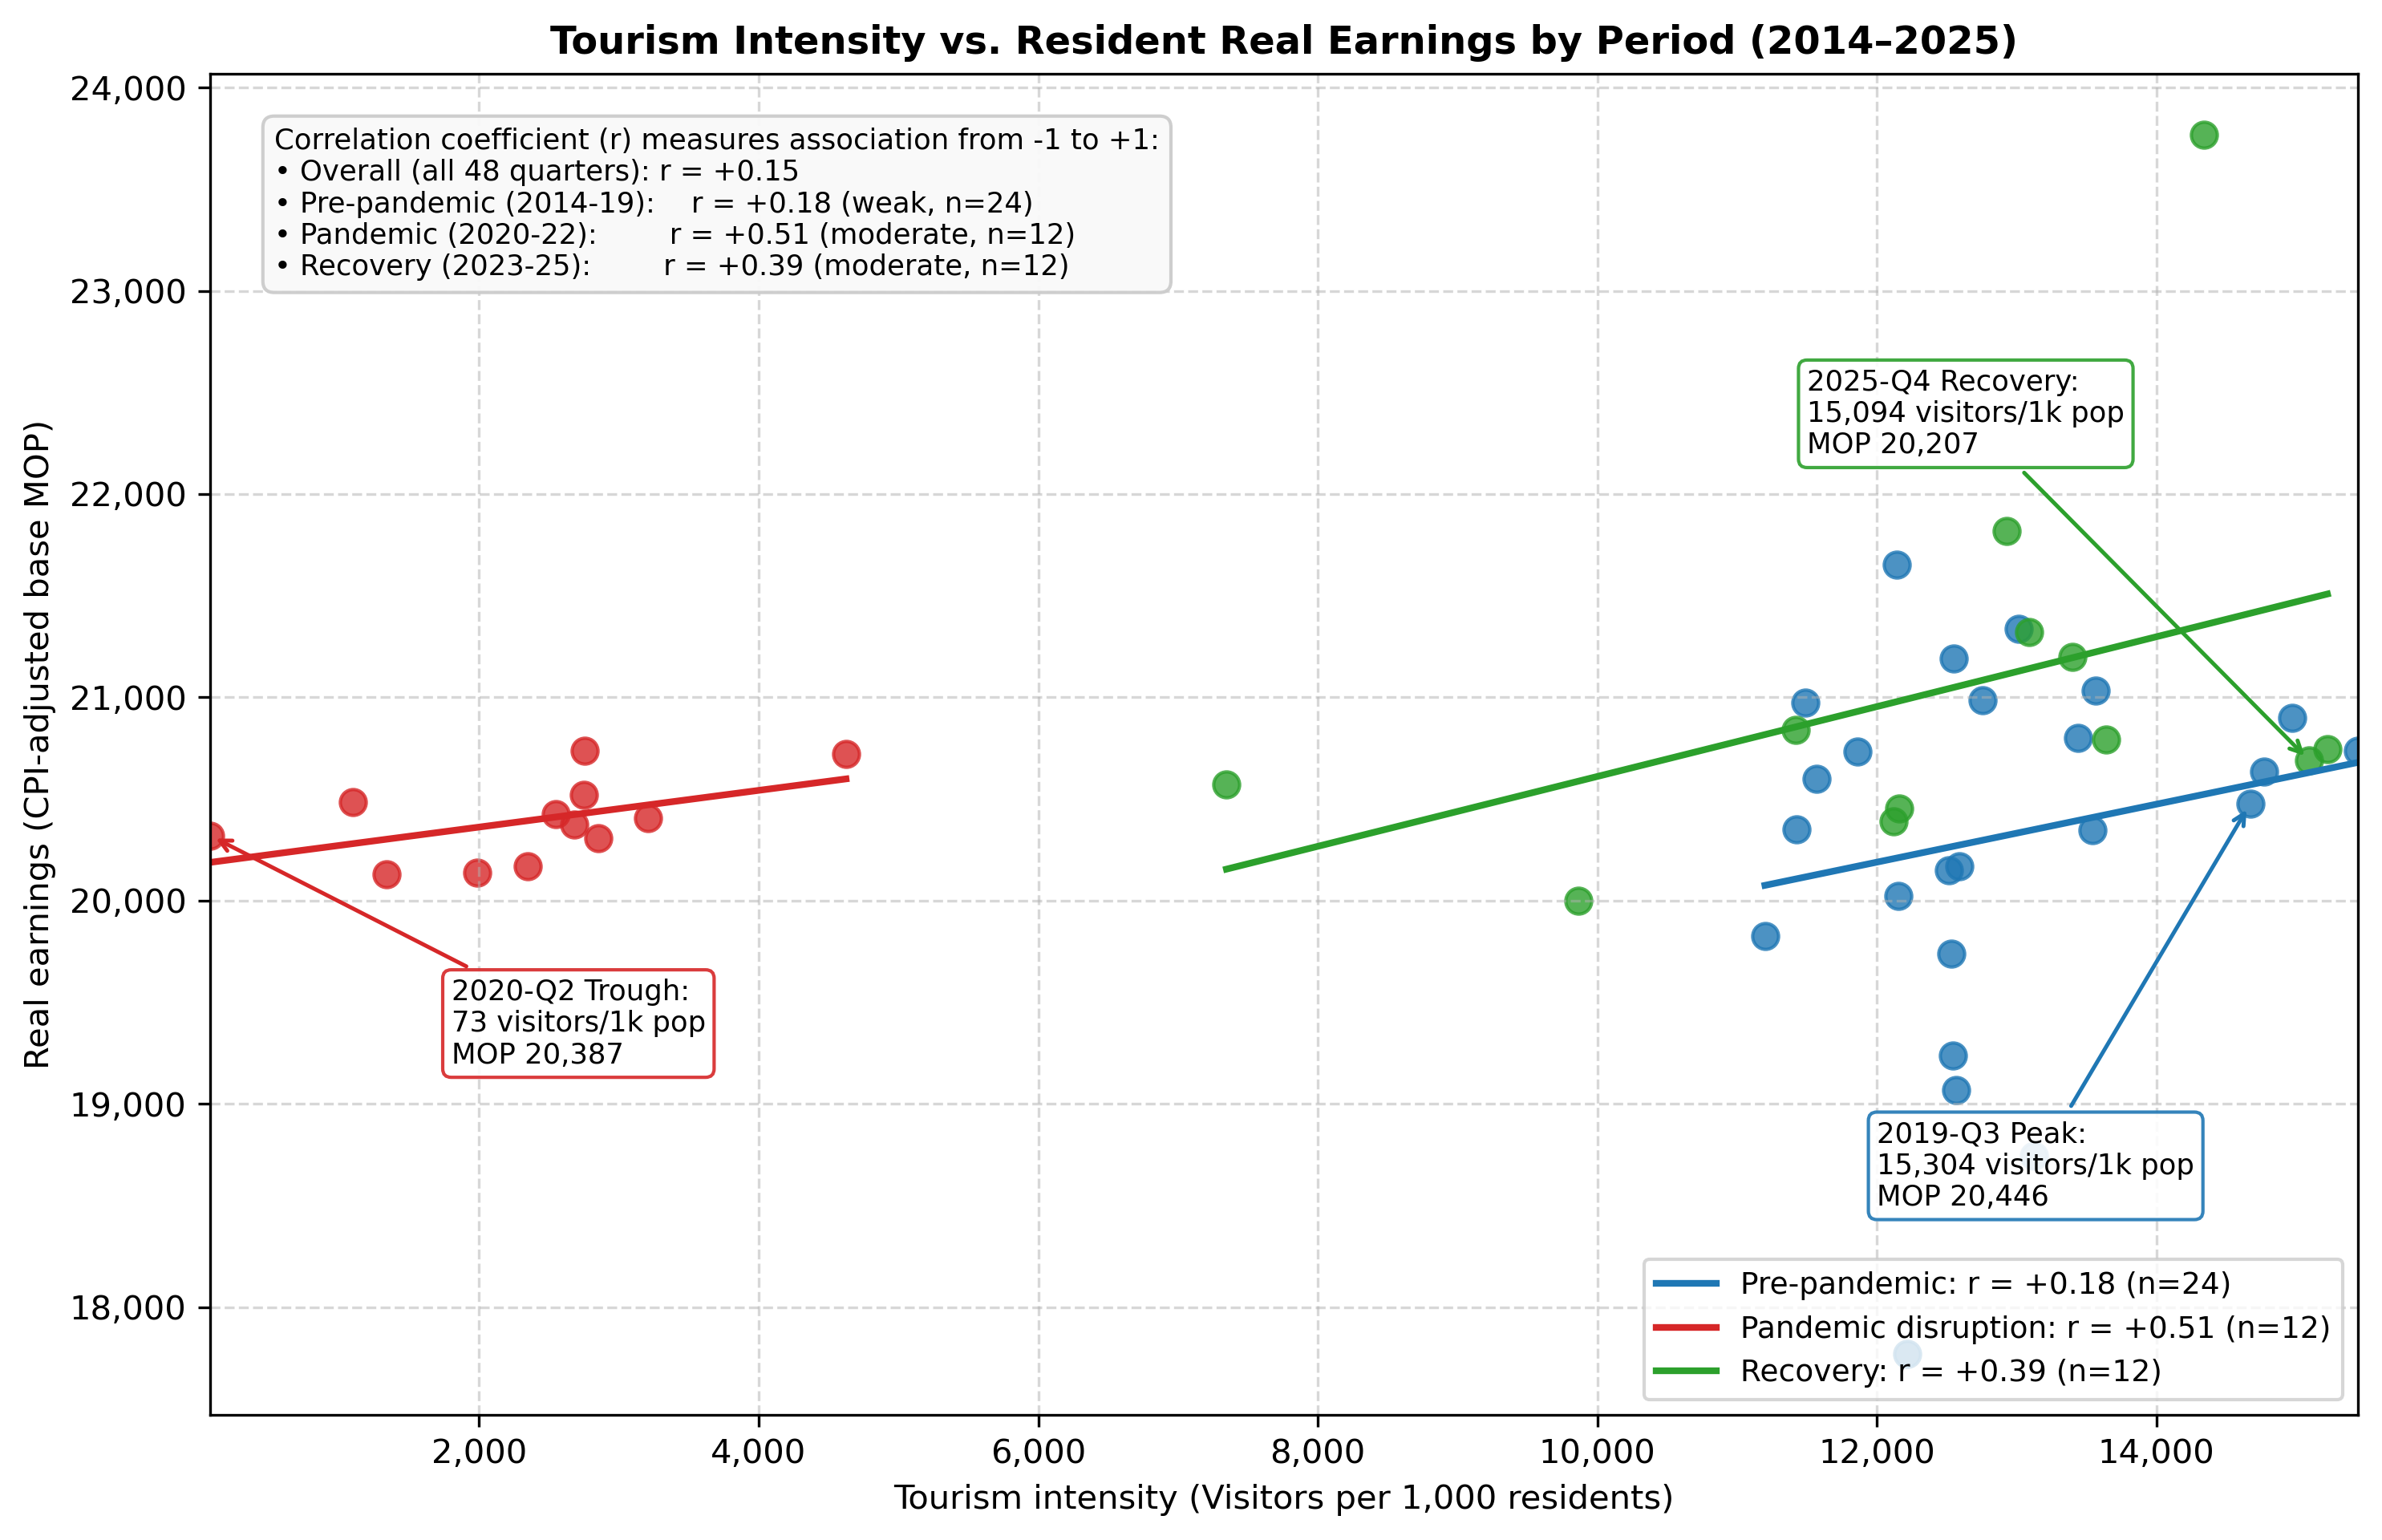

In [7]:
# Scatter plot of tourism intensity vs real earnings colored by period
fig, ax = plt.subplots(figsize=(10, 6.5))

# Calculate correlation for each period and overall
correlations = {}
for p_name in ["Pre-pandemic", "Pandemic disruption", "Recovery"]:
    sub = df[df["Phase"] == p_name]
    r_val, p_val = stats.pearsonr(sub["Visitors per 1,000 residents"], sub["Real earnings (base-period MOP)"])
    correlations[p_name] = (r_val, p_val, len(sub))

r_all, p_all = stats.pearsonr(df["Visitors per 1,000 residents"], df["Real earnings (base-period MOP)"])

# Plot points and regression lines
for p_name, color in period_colors.items():
    sub = df[df["Phase"] == p_name]
    r_val, p_val, n = correlations[p_name]
    sns.regplot(
        data=sub,
        x="Visitors per 1,000 residents",
        y="Real earnings (base-period MOP)",
        ax=ax,
        color=color,
        scatter_kws={"s": 60, "alpha": 0.8},
        line_kws={"linewidth": 2, "label": f"{p_name}: r = {r_val:+.2f} (n={n})"},
        ci=None
    )

# Annotate specific key quarters discussed in analysis
r_2020q2 = df[df["Quarter"] == "2020-Q2"].iloc[0]
ax.annotate("2020-Q2 Trough:\n73 visitors/1k pop\nMOP 20,387",
            xy=(r_2020q2["Visitors per 1,000 residents"], r_2020q2["Real earnings (base-period MOP)"]),
            xytext=(1800, 19200),
            arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.2),
            fontsize=8.5, bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffffff", edgecolor="#d62728", alpha=0.9))

r_2019q3 = df[df["Quarter"] == "2019-Q3"].iloc[0]
ax.annotate("2019-Q3 Peak:\n15,304 visitors/1k pop\nMOP 20,446",
            xy=(r_2019q3["Visitors per 1,000 residents"], r_2019q3["Real earnings (base-period MOP)"]),
            xytext=(12000, 18500),
            arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=1.2),
            fontsize=8.5, bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffffff", edgecolor="#1f77b4", alpha=0.9))

r_2025q4 = df[df["Quarter"] == "2025-Q4"].iloc[0]
ax.annotate("2025-Q4 Recovery:\n15,094 visitors/1k pop\nMOP 20,207",
            xy=(r_2025q4["Visitors per 1,000 residents"], r_2025q4["Real earnings (base-period MOP)"]),
            xytext=(11500, 22200),
            arrowprops=dict(arrowstyle="->", color="#2ca02c", lw=1.2),
            fontsize=8.5, bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffffff", edgecolor="#2ca02c", alpha=0.9))

ax.set_title("Tourism Intensity vs. Resident Real Earnings by Period (2014–2025)", fontsize=11.5, fontweight="bold")
ax.set_xlabel("Tourism intensity (Visitors per 1,000 residents)", fontsize=10)
ax.set_ylabel("Real earnings (CPI-adjusted base MOP)", fontsize=10)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f"{int(val):,}"))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f"{int(val):,}"))
ax.grid(True, linestyle="--", alpha=0.5)

# Add clear explanatory note box
note_text = (
    "Correlation coefficient (r) measures association from -1 to +1:\n"
    f"• Overall (all 48 quarters): r = {r_all:+.2f}\n"
    f"• Pre-pandemic (2014-19):    r = {correlations['Pre-pandemic'][0]:+.2f} (weak, n=24)\n"
    f"• Pandemic (2020-22):        r = {correlations['Pandemic disruption'][0]:+.2f} (moderate, n=12)\n"
    f"• Recovery (2023-25):        r = {correlations['Recovery'][0]:+.2f} (moderate, n=12)"
)
ax.text(0.03, 0.96, note_text, transform=ax.transAxes, verticalalignment="top",
        fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", facecolor="#f9f9f9", edgecolor="#ccc", alpha=0.95))

ax.legend(loc="lower right", fontsize=9, frameon=True)
plt.tight_layout()
plt.savefig(figures_dir / "fig4_phase_scatter_comovement.png", bbox_inches="tight")
plt.show()



### What We Notice from Figure 4 (Answering Sub-Question 3)

1. Pre-pandemic (2014–2019, r = +0.18, n = 24):
The correlation r is only +0.18 (weak). As shown by the blue points on the right of the chart, tourist intensity was already operating at high capacity (between 11,500 and 15,300 visitors per 1,000 residents, reaching the 2019-Q3 peak of 15,304 annotated on the chart). In normal busy years, quarterly changes in visitor numbers did not immediately move full-time base wages.

2. Pandemic disruption (2020–2022, r = +0.51, n = 12):
During the pandemic, the correlation r rose to +0.51 (moderate positive). When tourism collapsed to the 2020-Q2 trough (73.2 visitors per 1,000 residents, annotated with a red arrow), both tourism and wages contracted together, while temporary reopenings brought mild joint recoveries.

3. Recovery period (2023–2025, r = +0.39, n = 12):
During the recovery, r is +0.39 (moderate positive). Tourism intensity climbed back to 15,094 visitors per 1,000 residents by 2025-Q4 (annotated with a green arrow), coinciding with businesses reopening and a rebound in real earnings to 20,207 MOP.

## 8. Visualization F5: Comparing Distributions Across the Three Periods

To compare how each variable was distributed in the three periods, we used boxplots and strip plots (following what we practiced in Module 02 and Module 03).

- Subplot A shows quarterly visitor arrivals
- Subplot B shows visitor intensity per 1,000 residents
- Subplot C shows quarterly average CPI
- Subplot D shows real monthly earnings


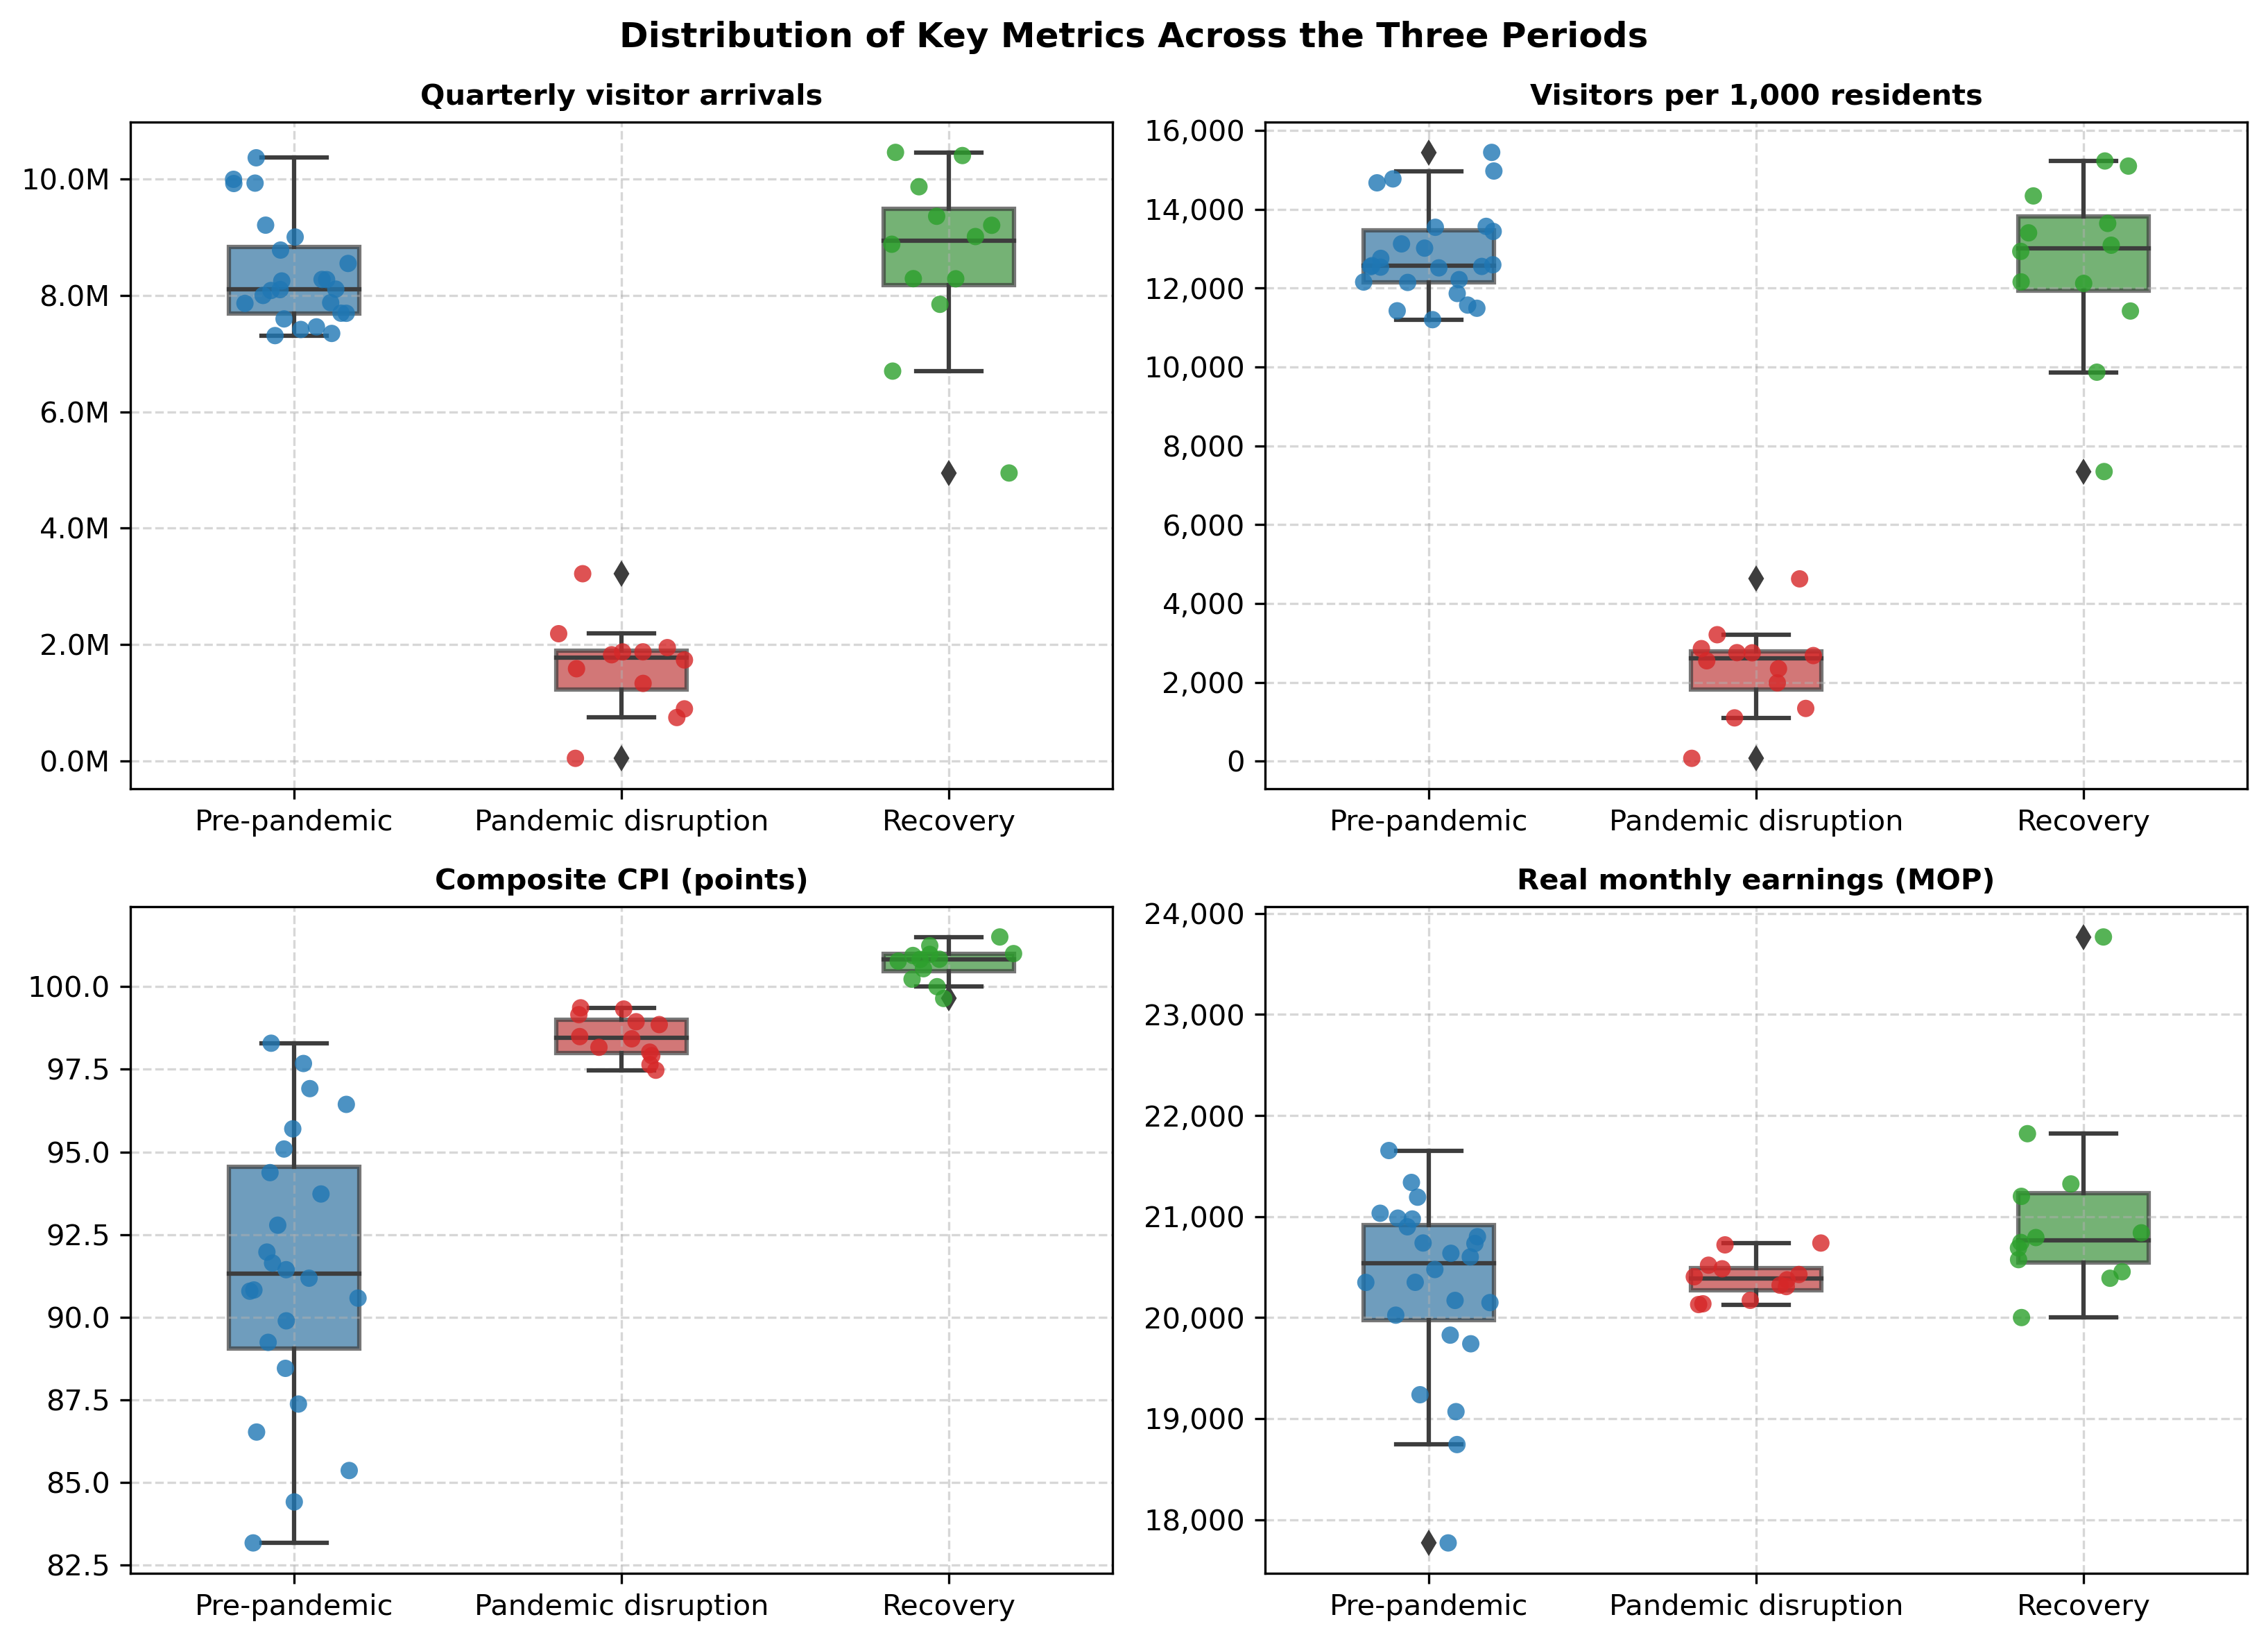

In [8]:
# Create 2x2 boxplots comparing distributions
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()

metrics = [
    ("Visitor arrivals", "Quarterly visitor arrivals", lambda x: f"{x/1e6:.1f}M"),
    ("Visitors per 1,000 residents", "Visitors per 1,000 residents", lambda x: f"{int(x):,}"),
    ("Composite CPI (quarterly mean)", "Composite CPI (points)", lambda x: f"{x:.1f}"),
    ("Real earnings (base-period MOP)", "Real monthly earnings (MOP)", lambda x: f"{int(x):,}")
]

period_order = ["Pre-pandemic", "Pandemic disruption", "Recovery"]

for i, (col, title, formatter) in enumerate(metrics):
    ax = axes[i]
    sns.boxplot(data=df, x="Phase", y=col, order=period_order, palette=period_colors, ax=ax, width=0.4, boxprops=dict(alpha=0.7))
    sns.stripplot(data=df, x="Phase", y=col, order=period_order, palette=period_colors, ax=ax, size=6, jitter=0.2, alpha=0.8)
    
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos, f=formatter: f(val)))
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Distribution of Key Metrics Across the Three Periods", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(figures_dir / "fig5_phase_distribution_small_multiples.png", bbox_inches="tight")
plt.show()


### What We Notice from Figure 5

1. Visitor arrivals and intensity:
The first two panels show how drastically tourism dropped during the pandemic. In the pre-pandemic and recovery periods, median quarterly visitors were both around 8 to 9 million (around 13,000 visitors per 1,000 residents), while the pandemic median was under 2 million.

2. CPI increased in steps:
CPI showed a clear upward step between each period: an average of about 90.8 pre-pandemic, 98.4 during the pandemic, and 101.4 during recovery.

3. Real earnings were relatively stable:
The boxplot for real earnings shows that the median remained between 20,000 and 21,000 MOP in all three periods. While tourism went through an extreme shock, full-time resident wages were relatively shielded from collapse.


## 9. Visualization F6: Interactive Plotly Chart (Module 04 Integration)

In Module 04, we learned how to use Plotly to build interactive web charts. Here, we created an interactive dashboard that lets you hover over any quarter to see the exact numbers for visitor arrivals, population, nominal salary, CPI, and real earnings.

We also saved this chart as an HTML file (`figures/fig6_interactive_tourism_affordability.html`) so it can be opened directly in any browser.


In [9]:
# Build an interactive Plotly chart with two synchronized rows
fig = make_subplots(
    rows=2, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.12,
    subplot_titles=("Tourism Intensity (Visitors per 1,000 Residents)", "Real Earnings Index (2014-Q1 = 100)")
)

# Custom hover data
custom_intensity = np.stack((
    df["Phase"],
    df["Visitor arrivals"],
    df["Population at quarter-end ('000)"]
), axis=-1)

# Top trace: Tourism intensity
fig.add_trace(
    go.Scatter(
        x=df["Quarter"],
        y=df["Visitors per 1,000 residents"],
        name="Visitor Intensity",
        mode="lines+markers",
        line=dict(color="#1f77b4", width=2),
        marker=dict(size=5),
        customdata=custom_intensity,
        hovertemplate="<b>%{x}</b><br>Period: %{customdata[0]}<br>Visitors: %{customdata[1]:,}<br>Population: %{customdata[2]:.1f}k<br>Intensity: %{y:,.0f} per 1k pop<extra></extra>"
    ),
    row=1, col=1
)

# Custom hover data for bottom trace
custom_earnings = np.stack((
    df["Phase"],
    df["Resident median earnings (MOP)"],
    df["Composite CPI (quarterly mean)"],
    df["Real earnings (base-period MOP)"]
), axis=-1)

# Bottom trace: Real earnings index
fig.add_trace(
    go.Scatter(
        x=df["Quarter"],
        y=df["Real earnings index (2014-Q1=100)"],
        name="Real Earnings Index",
        mode="lines+markers",
        line=dict(color="#2ca02c", width=2),
        marker=dict(size=5),
        customdata=custom_earnings,
        hovertemplate="<b>%{x}</b><br>Period: %{customdata[0]}<br>Nominal salary: MOP %{customdata[1]:,}<br>CPI: %{customdata[2]:.2f}<br>Real salary: MOP %{customdata[3]:,.0f}<br>Index: %{y:.1f}<extra></extra>"
    ),
    row=2, col=1
)

# Reference line at 100
fig.add_hline(y=100, line_dash="dash", line_color="gray", row=2, col=1)

fig.update_layout(
    title="Interactive Explorer: Tourism Intensity and Real Earnings in Macao (2014–2025)",
    height=650,
    hovermode="x unified",
    template="plotly_white",
    margin=dict(l=50, r=30, t=80, b=40)
)

fig.update_yaxes(title_text="Visitors / 1k pop", row=1, col=1)
fig.update_yaxes(title_text="Index (2014Q1=100)", row=2, col=1)
fig.update_xaxes(title_text="Quarter", row=2, col=1)

# Save to standalone HTML file
html_path = figures_dir / "fig6_interactive_tourism_affordability.html"
fig.write_html(str(html_path))
fig.show()


## 10. Conclusions
1. Tourism Pressure:
By the end of 2025, per-capita tourist pressure in Macao has fully returned to its pre-pandemic peak (over 15,000 visitors per 1,000 residents).
2. Resident Purchasing Power:
Local residents experienced almost no real purchasing power improvement (+5.0% over 12 years), as price inflation neutralized nominal wage increases.
3. Tourism-Earnings Link:
Tourism intensity and real earnings did not move together in normal times; they only co-moved strongly during the pandemic shock and the sudden post-2023 reopening.

## 11. Discussion, Limitations and Ground Rules

As students in this course, we tried to be careful not to jump to conclusions that our data cannot support. Here are the main limitations and ground rules we followed:

1. Correlation does not equal causation:
Even though tourist intensity and resident earnings moved together in some periods, we cannot claim that tourism directly caused salary changes. Many other things were happening at the same time, such as government cash handouts (the annual 10,000 MOP Wealth Partaking Scheme and electronic consumption vouchers during COVID-19), changes in interest rates, and overall economic conditions in mainland China. 

2. The DSEC salary indicator:
The DSEC salary indicator only covers full-time resident employees. It does not include non-resident workers (blue-card holders), who make up about a quarter of Macao's workforce and often work in hotels and restaurants. It also does not include part-time workers, retirees, or business owners. Therefore, our earnings measure represents full-time local workers, not every household in Macao.
